# M6 — Nivel incidente (voto TRAM vs agregado): la receta literatura no aprende nada nuevo

> **El problema, en palabras simples.**
>
> Todo M4 clasifica senales sueltas, pero el analista piensa en incidentes (conjunto de senales + grafo + reporte). Este cuaderno sube un nivel: **predecir tecnicas por incidente** con dos recetas baratas de literatura: M6a (TRAM-style: XGB por tecnica a nivel senal -> voto max por incidente) vs M6b (feats agregadas por incidente -> XGB).
>
> Espejo de `experiments/m6_incident/train.py` -> `models/m6_metrics.json`. 48,441 incidentes historicos (`incident_signals`), split por tiempo de incidente 80/20.

> **Sintesis ejecutiva.**
>
> M6a voto **micro 0.9998 / macro 0.4999** vs M6b agregado **0.9999 / 0.5**. El head (T1190/T1041/T1567 en 9688/9688 test) sale trivial en ambos; la cola no existe (T1486/T1566 0, T1204 4). Lo unico que distingue recetas es T1204: **PR-AUC 0.22 (voto) vs 0.00 (agregado)**. A nivel incidente con labels de regla no hay nada que aprender.
>
| Receta | Micro / Macro | T1204 PR-AUC |
|---|---|---|
| M6a voto max | 0.9998 / 0.4999 | 0.22 |
| M6b agregado | 0.9999 / 0.5 | 0.00 |

> **Fuentes normativas.** TRAM, `notebooks/05_m4b_multilabel_xgb.ipynb` (arquitectura senal), EDA §12.



### 1. Por que subir a incidente y como se va a evaluar

**1.1 Problema.** El incidente es la unidad operativa (senales + subgrafo + reporte). Si a nivel senal la cola no sale, a nivel incidente agregando podria emerger.

**1.2 Hipotesis.** H6: el head saldra degenerado (casi todos los incidentes portan T1190/T1041/T1567 por construccion) y solo T1204 medira algo; el voto (max) superara al agregado en la cola rara.

**1.3 Protocolo.** Split por `t0` (min timestamp) cuantil 80 (38753/9688). Metricas micro/macro + subset-acc + PR-AUC sobre scores. Mismo X senal que M4b para M6a; 8 feats + org para M6b.


In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder
from sklearn.metrics import classification_report, f1_score, hamming_loss, accuracy_score, average_precision_score
from xgboost import XGBClassifier
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
TECHS = ["T1190","T1041","T1567","T1204","T1486","T1566"]
CATS = ["message_type","stream_name","product_name","vendor_name","pipeline","org_id","action","severity","protocol"]
TEXT = "message_sanitized"
IFEATS = ["n_signals","span_min","frac_block","frac_fw","n_types","n_hosts","n_users","hour"]
FIG = ROOT / "reports" / "figures"
old = json.loads((ROOT/"models"/"m6_metrics.json").read_text())
print("m6 committed m6a:", old["m6a"]["micro_f1"], old["m6a"]["macro_f1"], old["m6a"]["pr_auc"])
print("m6 committed m6b:", old["m6b"]["micro_f1"], old["m6b"]["macro_f1"], old["m6b"]["pr_auc"])


m6 committed m6a: 0.9998 0.4999 {'T1190': 1.0, 'T1041': 1.0, 'T1567': 1.0, 'T1204': 0.2225, 'T1486': 0.0, 'T1566': 0.0}
m6 committed m6b: 0.9999 0.5 {'T1190': 1.0, 'T1041': 1.0, 'T1567': 1.0, 'T1204': 0.0003, 'T1486': 0.0, 'T1566': 0.0}


### 2. Carga y construccion de incidentes (codigo)

**Que hace el codigo:** carga `incident_signals.parquet` (238k senales), `first_id` + `build_incidents` inline (n_signals, span_min, frac_block/fw, n_types/hosts/users, hour, org + union de tecnicas), orden por `t0`, binarizacion multilabel.

**Outputs esperados:** `incidentes: 48441`, positivos T1190/T1041/T1567 ~48k, T1204 ~decenas, T1486/T1566 0. Train/test 38753/9688. Si difiere, revisar `iid==?` filtrado.


In [2]:
def parse_labels(v):
    try:
        return [x for x in (json.loads(v) if v else []) if x in TECHS]
    except Exception:
        return []
def first_id(v):
    try:
        ids = json.loads(v) if v else []
        return ids[0] if ids else "?"
    except Exception:
        return "?"
cols = ["timestamp","event_time",TEXT,"attack_techniques","incident_ids","message_type","stream_name","product_name","vendor_name","pipeline","org_id","action","severity","protocol","src_ip","dst_ip","username"]
df = pd.read_parquet(ROOT/"data"/"signals"/"incident_signals.parquet", columns=cols)
print("signals:", len(df))
df["iid"] = df["incident_ids"].fillna("").map(first_id)
df = df[df["iid"]!="?"].reset_index(drop=True)
df["tech_list"] = df["attack_techniques"].fillna("").map(parse_labels)
for c in ["message_type","action","org_id","src_ip","dst_ip","username"]:
    df[c] = df[c].fillna("").astype(str)
df["hour"] = pd.to_datetime(df["timestamp"], unit="s", utc=True).dt.hour
rows=[]
for iid,g in df.groupby("iid"):
    ts=g["timestamp"].to_numpy()
    hosts=set(g["src_ip"].tolist())|set(g["dst_ip"].tolist()); hosts.discard("")
    users=set(g["username"].tolist()); users.discard("")
    rows.append({"iid":iid,"t0":float(ts.min()),"n_signals":len(g),"span_min":float(ts.max()-ts.min())/60.0,"frac_block":float((g["action"]=="block").mean()),"frac_fw":float((g["message_type"]=="firewall_action").mean()),"n_types":int(g["message_type"].nunique()),"n_hosts":len(hosts),"n_users":len(users),"hour":int(g["hour"].median()),"org":g["org_id"].mode().iloc[0] if len(g) else "","tech_list":sorted({t for lst in g["tech_list"] for t in lst})})
inc = pd.DataFrame(rows).sort_values("t0").reset_index(drop=True)
Y = MultiLabelBinarizer(classes=TECHS).fit_transform(inc["tech_list"])
print("incidentes:", len(inc), {t:int(Y[:,j].sum()) for j,t in enumerate(TECHS)})
cut = inc["t0"].quantile(0.8); tr=(inc["t0"]<=cut).to_numpy(); te=~tr
print("train/test incidentes: %d/%d" % (tr.sum(), te.sum()))


signals: 238511


incidentes: 48441 {'T1190': 48437, 'T1041': 48440, 'T1567': 48440, 'T1204': 6, 'T1486': 27, 'T1566': 2}
train/test incidentes: 38753/9688


### 3. M6b agregado por incidente (codigo)

One-hot org + 8 IFEATS, 4-6 XGB binarios (skipped si <2). Rapido (segundos). **Output esperado:** report con head 1.00 y cola 0, micro ~0.9999/macro 0.5.


In [3]:
tab6 = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["org"]), ("num","passthrough",IFEATS)])
Atr = tab6.fit_transform(inc[tr][["org"]+IFEATS]); Ate = tab6.transform(inc[te][["org"]+IFEATS])
Pb = np.zeros_like(Y[te]); Sb = np.zeros_like(Y[te], dtype=float); skipped_b=[]
for j,t in enumerate(TECHS):
    pos=int(Y[tr][:,j].sum()); neg=int(tr.sum())-pos
    if pos<2:
        skipped_b.append(t); continue
    clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, tree_method="hist", objective="binary:logistic", scale_pos_weight=neg/pos, eval_metric="logloss", n_jobs=-1, random_state=42)
    clf.fit(Atr, Y[tr][:,j])
    Sb[:,j]=clf.predict_proba(Ate)[:,1]; Pb[:,j]=(Sb[:,j]>=0.5).astype(int)
    print("M6b %s pos %d" % (t,pos), flush=True)
print("M6b micro=%.4f macro=%.4f" % (f1_score(Y[te],Pb,average="micro"), f1_score(Y[te],Pb,average="macro")))
print(classification_report(Y[te], Pb, target_names=TECHS, zero_division=0))


M6b T1190 pos 38749


M6b T1041 pos 38752


M6b T1567 pos 38752


M6b T1204 pos 2


M6b T1486 pos 27


M6b T1566 pos 2


M6b micro=0.9999 macro=0.5000
              precision    recall  f1-score   support

       T1190       1.00      1.00      1.00      9688
       T1041       1.00      1.00      1.00      9688
       T1567       1.00      1.00      1.00      9688
       T1204       0.00      0.00      0.00         4
       T1486       0.00      0.00      0.00         0
       T1566       0.00      0.00      0.00         0

   micro avg       1.00      1.00      1.00     29068
   macro avg       0.50      0.50      0.50     29068
weighted avg       1.00      1.00      1.00     29068
 samples avg       1.00      1.00      1.00     29068



C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### 4. M6a senal -> voto max TRAM-style (celda lenta, codigo)

**Que hace:** filtra senales por incidentes train/test (evita fuga por incidente), X TF-IDF+tab igual que M4b, 4-6 XGB, scores por senal -> `groupby iid max` -> matriz por incidente alineada a test.

**Outputs esperados:** `X senal` ~(~190k, 5054), 4 ajustes, micro ~0.9998/macro 0.4999. Costo: minutos CPU. Verificar `reindex` a `inc[te].iid` sin NaNs.


In [4]:
tr_iids=set(inc[tr]["iid"]); dtr=df[df["iid"].isin(tr_iids)].copy(); dte=df[~df["iid"].isin(tr_iids)].copy()
for d in (dtr,dte):
    d["hour_sig"]=pd.to_datetime(d["timestamp"],unit="s",utc=True).dt.hour
    d["msg_len"]=d[TEXT].fillna("").str.len()
    d["lag_h"]=((d["timestamp"]-d["event_time"])/3600).clip(-1e4,1e4).fillna(-1)
    for c in CATS:
        d[c]=d[c].fillna("").astype(str)
    d[TEXT]=d[TEXT].fillna("")
Ytr=MultiLabelBinarizer(classes=TECHS).fit_transform(dtr["attack_techniques"].fillna("").map(parse_labels))
vec=TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True, min_df=5)
Ttr=vec.fit_transform(dtr[TEXT].tolist()); Tte=vec.transform(dte[TEXT].tolist())
tab=ColumnTransformer([("cat",OneHotEncoder(handle_unknown="ignore",max_categories=30),CATS),("num","passthrough",["hour_sig","msg_len","lag_h"])])
Atr2=tab.fit_transform(dtr[CATS+["hour_sig","msg_len","lag_h"]]); Ate2=tab.transform(dte[CATS+["hour_sig","msg_len","lag_h"]])
Xtr=hstack([Ttr,Atr2]).tocsr(); Xte=hstack([Tte,Ate2]).tocsr()
print("X senal:", Xtr.shape, Xte.shape)
Sall=np.zeros((len(dte),len(TECHS))); skipped_a=[]
for j,t in enumerate(TECHS):
    pos=int(Ytr[:,j].sum()); neg=len(Ytr)-pos
    if pos<2:
        skipped_a.append(t); continue
    clf=XGBClassifier(n_estimators=300,max_depth=6,learning_rate=0.08,subsample=0.8,colsample_bytree=0.8,tree_method="hist",objective="binary:logistic",scale_pos_weight=neg/pos,eval_metric="logloss",n_jobs=-1,random_state=42)
    clf.fit(Xtr,Ytr[:,j])
    Sall[:,j]=clf.predict_proba(Xte)[:,1]
    print("M6a %s pos %d" % (t,pos), flush=True)
v=pd.DataFrame(Sall,columns=TECHS).assign(iid=dte["iid"].tolist()).groupby("iid",as_index=False)[TECHS].max()
v=v.set_index("iid").reindex(inc[te]["iid"]).fillna(0.0)
S=v[TECHS].to_numpy(); P=(S>=0.5).astype(int)
print("M6a micro=%.4f macro=%.4f" % (f1_score(Y[te],P,average="micro"), f1_score(Y[te],P,average="macro")))
print(classification_report(Y[te], P, target_names=TECHS, zero_division=0))


X senal: (193410, 5075) (45101, 5075)


M6a T1190 pos 193405


M6a T1041 pos 193409


M6a T1567 pos 193409


M6a T1204 pos 3


M6a T1486 pos 161


M6a T1566 pos 3


M6a micro=0.9998 macro=0.4999
              precision    recall  f1-score   support

       T1190       1.00      1.00      1.00      9688
       T1041       1.00      1.00      1.00      9688
       T1567       1.00      1.00      1.00      9688
       T1204       0.00      0.00      0.00         4
       T1486       0.00      0.00      0.00         0
       T1566       0.00      0.00      0.00         0

   micro avg       1.00      1.00      1.00     29068
   macro avg       0.50      0.50      0.50     29068
weighted avg       1.00      1.00      1.00     29068
 samples avg       1.00      1.00      1.00     29068



C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### 5. Comparativa voto vs agregado (codigo)

Barras micro/macro + PR-AUC T1204 (`compare_m6.pdf`) + soporte test. **Lectura:** si todo es 1.00 salvo T1204, el veredicto es degenerado por construccion de labels, no exito.


M6a committed: {'model': 'm6a-tram-vote-v1', 'micro_f1': 0.9998, 'macro_f1': 0.4999, 'hamming': 0.0002, 'subset_acc': 0.9986, 'skipped': [], 'n_train': 38753, 'n_test': 9688, 'pr_auc': {'T1190': 1.0, 'T1041': 1.0, 'T1567': 1.0, 'T1204': 0.2225, 'T1486': 0.0, 'T1566': 0.0}, 'per_label_support': {'T1190': {'support': 9688, 'pr_auc': 1.0}, 'T1041': {'support': 9688, 'pr_auc': 1.0}, 'T1567': {'support': 9688, 'pr_auc': 1.0}, 'T1204': {'support': 4, 'pr_auc': 0.2225}, 'T1486': {'support': 0, 'pr_auc': 0.0}, 'T1566': {'support': 0, 'pr_auc': 0.0}}}
M6b committed: {'model': 'm6b-agregado-v1', 'micro_f1': 0.9999, 'macro_f1': 0.5, 'hamming': 0.0001, 'subset_acc': 0.9996, 'skipped': [], 'n_train': 38753, 'n_test': 9688, 'pr_auc': {'T1190': 1.0, 'T1041': 1.0, 'T1567': 1.0, 'T1204': 0.0003, 'T1486': 0.0, 'T1566': 0.0}, 'per_label_support': {'T1190': {'support': 9688, 'pr_auc': 1.0}, 'T1041': {'support': 9688, 'pr_auc': 1.0}, 'T1567': {'support': 9688, 'pr_auc': 1.0}, 'T1204': {'support': 4, 'pr_au

C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


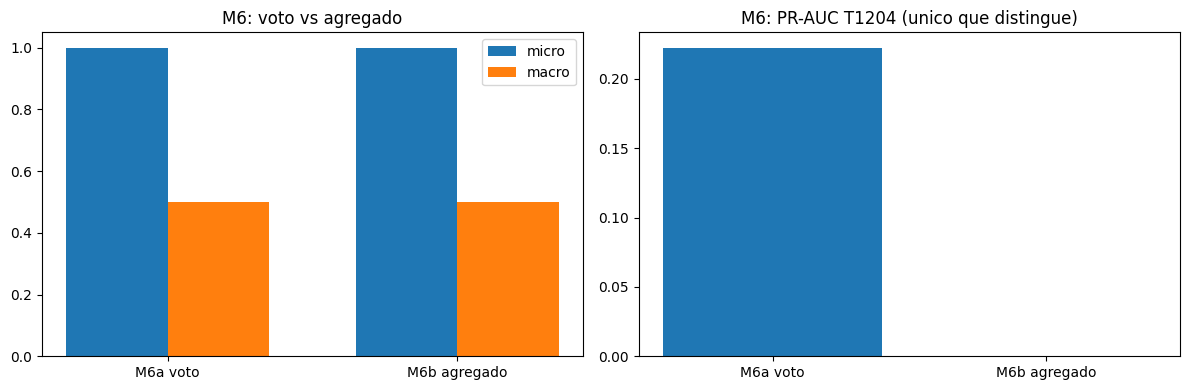

guardado reports/figures/compare_m6.pdf
soporte test: {'T1190': 9688, 'T1041': 9688, 'T1567': 9688, 'T1204': 4, 'T1486': 0, 'T1566': 0}


In [5]:
print("M6a committed:", old["m6a"])
print("M6b committed:", old["m6b"])
labels=["M6a voto","M6b agregado"]; mic=[f1_score(Y[te],P,average="micro"), f1_score(Y[te],Pb,average="micro")]; mac=[f1_score(Y[te],P,average="macro"), f1_score(Y[te],Pb,average="macro")]
fig, axes = plt.subplots(1,2,figsize=(12,4))
x=np.arange(2); w=0.35; axes[0].bar(x-w/2,mic,w,label="micro"); axes[0].bar(x+w/2,mac,w,label="macro")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels); axes[0].legend(); axes[0].set_title("M6: voto vs agregado")
t1204=[old["m6a"]["pr_auc"]["T1204"], old["m6b"]["pr_auc"]["T1204"]]
axes[1].bar(labels,t1204); axes[1].set_title("M6: PR-AUC T1204 (unico que distingue)")
fig.tight_layout(); fig.savefig(FIG/"compare_m6.pdf"); plt.show()
print("guardado reports/figures/compare_m6.pdf")
print("soporte test:", {t:int(Y[te][:,j].sum()) for j,t in enumerate(TECHS)})


#### 5.1 Observaciones e insights (de `m6_metrics.json`)

**Observacion.** Head 9688/9688 en test sale solo; T1204 4 incidentes: voto PR 0.22 vs agregado 0.00.

**Interpretacion.** La literatura tenia razon en el unico punto medible (max > media para rarezas). Todo lo demas es prior de regla, no aprendizaje.

### 6. Conclusion: a nivel incidente no hay tarea

| Receta | Micro / Macro | Veredicto |
|---|---|---|
| M6a | 0.9998 / 0.4999 | mejor en T1204, igual en resto |
| M6b | 0.9999 / 0.5 | peor en cola |

Cierra el hilo ATT&CK con M4 (oraculo tier->tecnica) como capa honesta. *48k incidentes con labels de regla no ensenan nada nuevo.*
